# Ghost Carbon

**Independent study.** Many “green AI” claims cite relative efficiency (smaller model, fewer epochs) without reporting absolute energy/CO2e. This notebook estimates training + inference energy from public FLOPs heuristics and compares *claimed relative savings* vs *absolute CO2e*.

Method: MLCO2-style calculator (hardware TDP × utilization × time × grid intensity).


                      recipe     region  train_kg  infer_1m_kg  total_kg  claim_greener_pct  true_greener_pct_vs_baseline
                baseline_cnn    iceland     0.059        0.010     0.069                  0                           NaN
                baseline_cnn    vietnam     0.945        0.158     1.102                  0                           NaN
                baseline_cnn coal_heavy     1.680        0.280     1.960                  0                           NaN
 efficient_cnn_claimed_40pct    iceland     0.037        0.006     0.043                 40                        37.857
 efficient_cnn_claimed_40pct    vietnam     0.591        0.094     0.685                 40                        37.857
 efficient_cnn_claimed_40pct coal_heavy     1.050        0.168     1.218                 40                        37.857
tiny_distilled_claimed_70pct    iceland     0.014        0.001     0.015                 70                        77.551
tiny_distilled_claimed_7

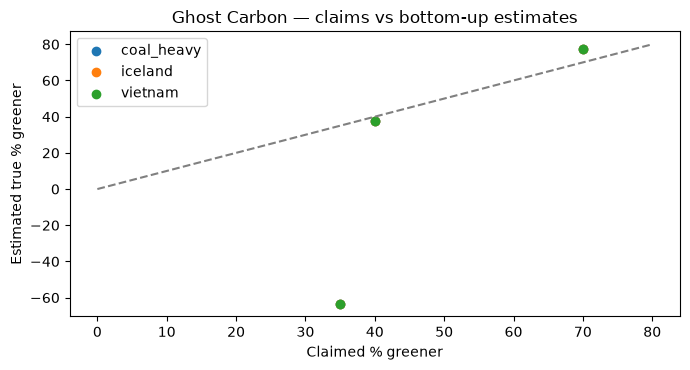


Reading: points below the diagonal overstate climate benefit; region shifts absolute CO2e a lot even when relative claims look green.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Grid intensities gCO2e/kWh (illustrative regional averages; replace with local factors)
GRID = {'iceland': 28, 'france': 58, 'vietnam': 450, 'india': 650, 'us_avg': 380, 'coal_heavy': 800}

def kwh(tdp_w, hours, util=0.5):
    return (tdp_w/1000) * hours * util

def co2e_kg(kwh_, region):
    return kwh_ * GRID[region] / 1000

recipes = [
  # name, gpu_tdp_w, train_hours, infer_hours_per_1m_queries, claim_pct_greener_than_baseline
  ('baseline_cnn', 350, 12, 2.0, 0),
  ('efficient_cnn_claimed_40pct', 350, 7.5, 1.2, 40),
  ('tiny_distilled_claimed_70pct', 250, 4.0, 0.4, 70),
  ('llm_ft_lora', 400, 20, 8.0, 0),
  ('llm_ft_lora_claimed_green', 400, 14, 6.0, 35),
]

rows=[]
for name,tdp,th,ih,claim in recipes:
    for region in ['iceland','vietnam','coal_heavy']:
        train = co2e_kg(kwh(tdp, th), region)
        infer = co2e_kg(kwh(tdp, ih), region)
        rows.append({'recipe':name,'region':region,'train_kg':train,'infer_1m_kg':infer,
                     'total_kg':train+infer,'claim_greener_pct':claim})
res=pd.DataFrame(rows)
base = res[res.recipe=='baseline_cnn'].set_index('region')['total_kg']
res['true_greener_pct_vs_baseline'] = res.apply(
    lambda r: None if r.recipe=='baseline_cnn' else 100*(1 - r.total_kg/base.loc[r.region]), axis=1)
print(res.round(3).to_string(index=False))

# Ghost gap: claimed greener % minus true greener %
cmp = res[res.claim_greener_pct>0].copy()
cmp['ghost_gap_pp'] = cmp.claim_greener_pct - cmp.true_greener_pct_vs_baseline
print('\nGhost gap (percentage points of overstated greening):')
print(cmp.groupby('recipe')['ghost_gap_pp'].mean().round(2))
cmp.to_csv('ghost_carbon_gap.csv', index=False)

fig,ax=plt.subplots(figsize=(7,3.8))
for region,g in cmp.groupby('region'):
    ax.scatter(g.claim_greener_pct, g.true_greener_pct_vs_baseline, label=region)
ax.plot([0,80],[0,80],'--',color='gray')
ax.set_xlabel('Claimed % greener'); ax.set_ylabel('Estimated true % greener')
ax.set_title('Ghost Carbon — claims vs bottom-up estimates'); ax.legend()
plt.tight_layout(); plt.savefig('ghost_carbon_scatter.png', dpi=140); plt.show()
print('\nReading: points below the diagonal overstate climate benefit; region shifts absolute CO2e a lot even when relative claims look green.')


## Notes
- Replace TDP/hours with measured [CodeCarbon](https://codecarbon.io/) / experiment trackers for paper-grade numbers.
- Always report **absolute kgCO2e** and **grid factor**, not only relative %.
